# 05 · Comparación integrada de modelos

**Proyecto:** popularidad histórica de canciones de Spotify Tracks  
**Propósito:** reproducir el núcleo común de Lucas, Ignacio y César, comparar sus extensiones con particiones controladas y producir las cifras para el README y la presentación.

Este notebook vuelve a cargar y preparar la fuente original. No consume resultados guardados de 04a–04c. `track_id` es la unidad de observación; la popularidad, nombres y artistas no se usan como predictores. Las conclusiones describen esta muestra histórica, balanceada artificialmente por género.

## 1. Fuente, preparación y controles

Se usa la fuente versionada y las funciones de preparación del proyecto. Antes de modelar se verifica que cada canción aparezca una sola vez, que los predictores tengan valores válidos y que la variable objetivo esté en su rango documentado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from spotify_popularity.analysis.exploratory import validate_processed_dataset
from spotify_popularity.config import PROJECT_PATHS
from spotify_popularity.data.loader import load_raw_dataset
from spotify_popularity.data.preparation import prepare_modeling_dataset
from spotify_popularity.data.provenance import sha256_file
from spotify_popularity.modeling.protocol import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    SEED,
    GenreBinarizer,
    model_pipeline,
    primary_artist,
    regression_metrics,
    split_primary_artist_ids,
    split_track_ids,
    top_decile_kpi,
)

source_hash = sha256_file(PROJECT_PATHS.raw_dataset)
data, preparation = prepare_modeling_dataset(load_raw_dataset())
controls = validate_processed_dataset(data)
assert controls["shape"] == (89_740, 20)
assert controls["missing_cells"] == 0
assert controls["duplicate_track_ids"] == 0
assert controls["non_positive_durations"] == 0
assert controls["empty_genres"] == 0
assert data["popularity"].between(0, 100).all()

print(f"Fuente SHA-256: {source_hash}")
print(f"Python/scikit-learn/pandas: {sklearn.__version__} / {pd.__version__}")
print(f"Preparación: {preparation}")
display(pd.Series(controls, name="valor").to_frame())

Fuente SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
Python/scikit-learn/pandas: 1.9.0 / 2.3.3
Preparación: PreparationSummary(input_rows=114000, invalid_rows_removed=1, output_rows=89740, repeated_track_ids_consolidated=24259)


,valor
shape,"(89740, 20)"
missing_cells,0
unique_track_ids,89740
duplicate_track_ids,0
non_positive_durations,0
empty_genres,0


## 2. Particiones reproducibles

La evaluación aleatoria usa el protocolo común: 80 % de canciones para entrenamiento, 20 % para prueba y, dentro del entrenamiento, una validación independiente para elegir parámetros. La evaluación agrupada crea otra partición desde cero: artistas principales completos quedan en prueba y una validación agrupada propia selecciona parámetros. Las dos pruebas no se mezclan.

In [2]:
feature_columns = list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES) + ["track_genres"]
indexed = data.set_index("track_id", drop=False)

random_split = split_track_ids(data)
fit_data = indexed.loc[list(random_split.fit_ids)]
validation_data = indexed.loc[list(random_split.validation_ids)]
train_data = indexed.loc[list(random_split.train_ids)]
test_data = indexed.loc[list(random_split.test_ids)]
X_fit, y_fit = fit_data[feature_columns], fit_data["popularity"]
X_validation, y_validation = validation_data[feature_columns], validation_data["popularity"]
X_train, y_train = train_data[feature_columns], train_data["popularity"]
X_test, y_test = test_data[feature_columns], test_data["popularity"]
assert set(random_split.fit_ids) | set(random_split.validation_ids) == set(random_split.train_ids)
assert not set(random_split.train_ids) & set(random_split.test_ids)
assert len(random_split.train_ids) == 71_792 and len(random_split.test_ids) == 17_948

print(f"Partición aleatoria, semilla {SEED}")
print(f"Ajuste: {len(fit_data):,}; validación: {len(validation_data):,}; entrenamiento final: {len(train_data):,}; prueba: {len(test_data):,}")
print(f"Huella de IDs de prueba: {random_split.test_sha256}")
display(pd.DataFrame({"partición": ["ajuste", "validación", "prueba"], "canciones": [len(fit_data), len(validation_data), len(test_data)]}))

Partición aleatoria, semilla 42
Ajuste: 57,433; validación: 14,359; entrenamiento final: 71,792; prueba: 17,948
Huella de IDs de prueba: 7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318


,partición,canciones
0,ajuste,57433
1,validación,14359
2,prueba,17948


## 3. Núcleo supervisado común

La referencia predice la mediana del entrenamiento. Ridge regulariza un modelo lineal; el árbol representa reglas no lineales. Para ambos se compara el conjunto completo de predictores con la variante sin géneros. La selección usa únicamente MAE de validación; RMSE y complejidad sirven para desempatar. Los pipelines ajustan codificadores y escalas dentro de cada partición.

In [3]:
ridge_grid = [{"alpha": alpha} for alpha in (0.1, 1.0, 10.0, 100.0)]
tree_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf}
    for depth in (5, 10, 15)
    for leaf in (20, 100)
]
parameter_grids = {"Ridge": ridge_grid, "Árbol": tree_grid}


def estimator_for(model_name, parameters):
    if model_name == "Ridge":
        return Ridge(**parameters)
    return DecisionTreeRegressor(random_state=SEED, **parameters)


def complexity_for(model_name, parameters):
    return -parameters["alpha"] if model_name == "Ridge" else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]


def pipeline_for(model_name, parameters, *, include_genres=True):
    return model_pipeline(estimator_for(model_name, parameters), include_genres=include_genres)

random_validation_rows = []
for variant, include_genres in (("completo", True), ("sin_géneros", False)):
    for model_name, grid in parameter_grids.items():
        for parameters in grid:
            candidate = pipeline_for(model_name, parameters, include_genres=include_genres)
            candidate.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, candidate.predict(X_validation))
            random_validation_rows.append({
                "variante": variant,
                "modelo": model_name,
                "parámetros": parameters,
                "complejidad": complexity_for(model_name, parameters),
                **scores,
            })

random_validation = pd.DataFrame(random_validation_rows)
random_selected = (
    random_validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .reset_index(drop=True)
)
random_reference_validation = DummyRegressor(strategy="median").fit(X_fit, y_fit)
random_ref_val_metrics = regression_metrics(y_validation, random_reference_validation.predict(X_validation))
print("Referencia en validación:", random_ref_val_metrics)
print("Configuraciones elegidas sin consultar la prueba:")
display(random_selected[["variante", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

Referencia en validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}
Configuraciones elegidas sin consultar la prueba:


,variante,modelo,parámetros,MAE,RMSE,R2
0,completo,Ridge,{'alpha': 0.1},11.786,16.430,0.360
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.393,18.312,0.205
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.627,19.830,0.067
3,sin_géneros,Ridge,{'alpha': 0.1},16.581,20.162,0.036


### Evaluación única en la prueba aleatoria

Tras fijar parámetros en validación, se reajusta cada variante declarada con todo el entrenamiento y se mide una vez en la prueba reservada. La mejora de MAE se expresa respecto de la referencia mediana.

In [4]:
random_reference = DummyRegressor(strategy="median").fit(X_train, y_train)
random_predictions = {"Referencia mediana": random_reference.predict(X_test)}
random_test_rows = [{
    "variante": "referencia", "modelo": "Dummy mediana", "parámetros": "mediana",
    **regression_metrics(y_test, random_predictions["Referencia mediana"]),
}]

for row in random_selected.itertuples(index=False):
    include_genres = row.variante == "completo"
    name = f"{row.modelo} / {row.variante}"
    fitted = pipeline_for(row.modelo, row.parámetros, include_genres=include_genres)
    fitted.fit(X_train, y_train)
    random_predictions[name] = fitted.predict(X_test)
    random_test_rows.append({
        "variante": row.variante, "modelo": row.modelo, "parámetros": row.parámetros,
        **regression_metrics(y_test, random_predictions[name]),
    })

random_test = pd.DataFrame(random_test_rows)
random_baseline_mae = random_test.loc[random_test["modelo"].eq("Dummy mediana"), "MAE"].iloc[0]
random_test["mejora_MAE_puntos"] = random_baseline_mae - random_test["MAE"]
random_test["mejora_MAE_pct"] = 100 * random_test["mejora_MAE_puntos"] / random_baseline_mae
random_test = random_test.sort_values(["MAE", "RMSE"]).reset_index(drop=True)
display(random_test.round(3))

best_random = random_selected.sort_values(["MAE", "RMSE", "complejidad"]).iloc[0]
random_candidate_name = f"{best_random['modelo']} / {best_random['variante']}"
random_candidate_predictions = random_predictions[random_candidate_name]
random_kpi = top_decile_kpi(test_data["track_id"], y_test, random_candidate_predictions)
print("Candidato fijado en validación:", random_candidate_name)
print("KPI retrospectivo del 10 % superior:", random_kpi)

,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
0,completo,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
1,completo,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.508,18.460,0.198,2.742,15.898
2,sin_géneros,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",15.693,19.834,0.074,1.557,9.026
3,sin_géneros,Ridge,{'alpha': 0.1},16.671,20.223,0.037,0.580,3.360
4,referencia,Dummy mediana,mediana,17.250,20.612,-0.000,0.000,0.000


Candidato fijado en validación: Ridge / completo
KPI retrospectivo del 10 % superior: {'seleccionadas': 1795, 'populares_en_seleccion': 159, 'populares_en_prueba': 653, 'prevalencia': 0.03638288388678404, 'precision': 0.08857938718662953, 'recall': 0.2434915773353752, 'lift': 2.434644473546136}


## 4. Aporte de Ignacio: duración y escalado robusto

Se reproduce el diseño factorial 2×2: tratamiento estándar, `log1p(duration_ms)`, escalado robusto y combinación. Las transformaciones viven dentro del pipeline. Cada tratamiento elige Ridge y árbol con la misma validación aleatoria y usa la prueba compartida solo para cuantificar el desempeño final.

In [5]:
treatments = {
    "estándar": (False, "standard"),
    "log_duración": (True, "standard"),
    "robusto": (False, "robust"),
    "log_duración_robusto": (True, "robust"),
}


def treatment_pipeline(estimator, treatment):
    log_duration, scaler_name = treatments[treatment]
    scaler_factory = RobustScaler if scaler_name == "robust" else StandardScaler
    transformers = []
    if log_duration:
        transformers.extend([
            ("duration", Pipeline([
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", scaler_factory()),
            ]), ["duration_ms"]),
            ("numeric", scaler_factory(), [column for column in NUMERIC_FEATURES if column != "duration_ms"]),
        ])
    else:
        transformers.append(("numeric", scaler_factory(), list(NUMERIC_FEATURES)))
    transformers.extend([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), list(CATEGORICAL_FEATURES)),
        ("genres", GenreBinarizer(), ["track_genres"]),
    ])
    preprocessing = ColumnTransformer(transformers, remainder="drop", sparse_threshold=1.0)
    return Pipeline([("preprocessing", preprocessing), ("model", estimator)])

sensitivity_validation_rows = []
for treatment in treatments:
    for model_name, grid in parameter_grids.items():
        for parameters in grid:
            model = treatment_pipeline(estimator_for(model_name, parameters), treatment)
            model.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, model.predict(X_validation))
            sensitivity_validation_rows.append({
                "tratamiento": treatment,
                "modelo": model_name,
                "parámetros": parameters,
                "complejidad": complexity_for(model_name, parameters),
                **scores,
            })

sensitivity_validation = pd.DataFrame(sensitivity_validation_rows)
sensitivity_selected = (
    sensitivity_validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["tratamiento", "modelo"], sort=False)
    .head(1)
    .reset_index(drop=True)
)
display(sensitivity_selected[["tratamiento", "modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

sensitivity_rows = []
for row in sensitivity_selected.itertuples(index=False):
    model = treatment_pipeline(estimator_for(row.modelo, row.parámetros), row.tratamiento)
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    scores = regression_metrics(y_test, prediction)
    sensitivity_rows.append({"tratamiento": row.tratamiento, "modelo": row.modelo, **scores})
sensitivity_test = pd.DataFrame(sensitivity_rows)
display(sensitivity_test.sort_values(["tratamiento", "MAE"]).round(3))

,tratamiento,modelo,parámetros,MAE,RMSE,R2
0,estándar,Ridge,{'alpha': 0.1},11.786,16.430,0.360
1,robusto,Ridge,{'alpha': 0.1},11.786,16.430,0.360
2,log_duración,Ridge,{'alpha': 0.1},11.788,16.430,0.360
3,log_duración_robusto,Ridge,{'alpha': 0.1},11.788,16.430,0.360
4,estándar,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.393,18.312,0.205
5,log_duración,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.393,18.312,0.205
6,robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.393,18.312,0.205
7,log_duración_robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.393,18.312,0.205


,tratamiento,modelo,MAE,RMSE,R2
0,estándar,Ridge,11.915,16.643,0.348
4,estándar,Árbol,14.508,18.460,0.198
2,log_duración,Ridge,11.914,16.643,0.348
5,log_duración,Árbol,14.508,18.460,0.198
3,log_duración_robusto,Ridge,11.914,16.643,0.348
7,log_duración_robusto,Árbol,14.507,18.460,0.198
1,robusto,Ridge,11.915,16.643,0.348
6,robusto,Árbol,14.507,18.460,0.198


## 5. Errores por popularidad, contenido explícito y género

Se diagnostica el candidato escogido en validación. Los rangos se fijaron antes de mirar los errores. Para género se expanden las etiquetas después de predecir; una canción puede aparecer en varios grupos, por lo que se informa el soporte por canciones únicas.

In [6]:
error_frame = pd.DataFrame({
    "track_id": test_data["track_id"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicho": random_candidate_predictions,
    "explicit": test_data["explicit"].to_numpy(),
    "track_genres": test_data["track_genres"].to_numpy(),
})
error_frame["error_abs"] = (error_frame["actual"] - error_frame["predicho"]).abs()
error_frame["sesgo"] = error_frame["predicho"] - error_frame["actual"]
error_frame["error_sq"] = np.square(error_frame["actual"] - error_frame["predicho"])
error_frame["rango"] = np.select(
    [
        error_frame["actual"].eq(0),
        error_frame["actual"].between(0, 35, inclusive="neither"),
        error_frame["actual"].between(35, 70, inclusive="left"),
        error_frame["actual"].ge(70),
    ],
    ["0", "(0,35)", "[35,70)", "[70,100]"],
    default="sin_clasificar",
)
range_metrics = error_frame.groupby("rango", sort=False).agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"), sesgo_medio=("sesgo", "mean")
).round(3)
display(range_metrics)

explicit_metrics = error_frame.groupby("explicit", sort=True).agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"),
    RMSE=("error_sq", lambda values: float(np.sqrt(values.mean()))),
    sesgo_medio=("sesgo", "mean"),
    populares_ge_70=("actual", lambda values: int(values.ge(70).sum())),
).round(3)
display(explicit_metrics)

genre_frame = error_frame.assign(genero=error_frame["track_genres"].str.split("|")).explode("genero")
genre_frame = genre_frame.loc[genre_frame["genero"].notna()]
genre_metrics = genre_frame.groupby("genero").agg(
    canciones=("track_id", "nunique"), MAE=("error_abs", "mean"),
    populares_ge_70=("actual", lambda x: int(x.ge(70).sum())),
).query("canciones >= 100").sort_values(["MAE", "canciones"], ascending=[False, False]).round(3)
print(f"Géneros que cumplen soporte mínimo de 100: {len(genre_metrics)}")
display(genre_metrics)

,canciones,MAE,sesgo_medio
rango,,,
"(0,35)",7361,8.040,6.344
"[35,70)",8071,10.546,-8.607
0,1863,24.448,24.148
"[70,100]",653,36.759,-36.759


,canciones,MAE,RMSE,sesgo_medio,populares_ge_70
explicit,,,,,
False,16431,11.704,16.392,-0.120,543
True,1517,14.198,19.153,0.117,110


Géneros que cumplen soporte mínimo de 100: 114


,canciones,MAE,populares_ge_70
genero,,,
electro,223,32.532,59
dance,182,32.175,47
house,206,31.551,52
edm,197,29.726,46
alternative,199,28.757,36
...,...,...,...
forro,206,3.212,0
grindcore,212,3.191,0
sertanejo,207,3.180,0


## 6. Generalización a artistas principales no vistos

La prueba agrupada usa otra semilla reproducible y un `GroupShuffleSplit` por primer artista de `artists`. No existe solapamiento de artistas principales entre entrenamiento y prueba. Se seleccionan parámetros con la validación agrupada propia, se vuelve a ajustar sobre el entrenamiento agrupado completo y se evalúa en su prueba una sola vez. También se cuentan colaboraciones secundarias que cruzan la partición.

In [7]:
artist_split = split_primary_artist_ids(data)
artist_fit = indexed.loc[list(artist_split.fit_ids)]
artist_validation = indexed.loc[list(artist_split.validation_ids)]
artist_train = indexed.loc[list(artist_split.train_ids)]
artist_test = indexed.loc[list(artist_split.test_ids)]
X_artist_fit, y_artist_fit = artist_fit[feature_columns], artist_fit["popularity"]
X_artist_val, y_artist_val = artist_validation[feature_columns], artist_validation["popularity"]
X_artist_train, y_artist_train = artist_train[feature_columns], artist_train["popularity"]
X_artist_test, y_artist_test = artist_test[feature_columns], artist_test["popularity"]


def primary_set(frame):
    return set(frame["artists"].map(primary_artist))


def secondary_set(frame):
    return {
        name.strip().casefold()
        for value in frame["artists"]
        for name in str(value).split(";")[1:]
        if name.strip()
    }

assert not primary_set(artist_train) & primary_set(artist_test)
assert not primary_set(artist_fit) & primary_set(artist_validation)
secondary_overlap = secondary_set(artist_train) & secondary_set(artist_test)
secondary_test_any_overlap = secondary_set(artist_test) & (
    secondary_set(artist_train) | primary_set(artist_train)
)
shared_secondary_tracks = sum(
    bool({name.strip().casefold() for name in str(value).split(";")[1:] if name.strip()} & secondary_test_any_overlap)
    for value in artist_test["artists"]
)
print(f"Ajuste/validación/entrenamiento/prueba: {len(artist_fit):,} / {len(artist_validation):,} / {len(artist_train):,} / {len(artist_test):,}")
print(f"Artistas principales entrenamiento/prueba: {len(primary_set(artist_train)):,} / {len(primary_set(artist_test)):,}")
print(f"Artistas principales compartidos: {len(primary_set(artist_train) & primary_set(artist_test))}")
print(f"Artistas secundarios presentes en ambas particiones: {len(secondary_overlap):,}")
print(f"Canciones de prueba con colaboradores secundarios que aparecen en entrenamiento: {shared_secondary_tracks:,} de {len(artist_test):,}")
print(f"Huella de IDs de prueba agrupada: {artist_split.test_sha256}")

artist_reference_validation = DummyRegressor(strategy="median").fit(X_artist_fit, y_artist_fit)
artist_ref_val = regression_metrics(y_artist_val, artist_reference_validation.predict(X_artist_val))
artist_validation_rows = []
for model_name, grid in parameter_grids.items():
    for parameters in grid:
        model = pipeline_for(model_name, parameters, include_genres=True)
        model.fit(X_artist_fit, y_artist_fit)
        scores = regression_metrics(y_artist_val, model.predict(X_artist_val))
        artist_validation_rows.append({
            "modelo": model_name, "parámetros": parameters,
            "complejidad": complexity_for(model_name, parameters), **scores,
        })
artist_validation_scores = pd.DataFrame(artist_validation_rows)
artist_selected = artist_validation_scores.sort_values(
    ["MAE", "RMSE", "complejidad"]
).groupby("modelo", sort=False).head(1).reset_index(drop=True)
print("Referencia en validación agrupada:", artist_ref_val)
display(artist_selected[["modelo", "parámetros", "MAE", "RMSE", "R2"]].round(3))

artist_reference = DummyRegressor(strategy="median").fit(X_artist_train, y_artist_train)
artist_predictions = {"Dummy mediana": artist_reference.predict(X_artist_test)}
artist_test_rows = [{"modelo": "Dummy mediana", "parámetros": "mediana", **regression_metrics(y_artist_test, artist_predictions["Dummy mediana"])}]
for row in artist_selected.itertuples(index=False):
    model = pipeline_for(row.modelo, row.parámetros, include_genres=True)
    model.fit(X_artist_train, y_artist_train)
    artist_predictions[row.modelo] = model.predict(X_artist_test)
    artist_test_rows.append({"modelo": row.modelo, "parámetros": row.parámetros, **regression_metrics(y_artist_test, artist_predictions[row.modelo])})
artist_test_scores = pd.DataFrame(artist_test_rows)
artist_baseline_mae = artist_test_scores.loc[artist_test_scores["modelo"].eq("Dummy mediana"), "MAE"].iloc[0]
artist_test_scores["mejora_MAE_puntos"] = artist_baseline_mae - artist_test_scores["MAE"]
artist_test_scores["mejora_MAE_pct"] = 100 * artist_test_scores["mejora_MAE_puntos"] / artist_baseline_mae
display(artist_test_scores.round(3))

Ajuste/validación/entrenamiento/prueba: 57,176 / 14,371 / 71,547 / 18,193
Artistas principales entrenamiento/prueba: 14,111 / 3,528
Artistas principales compartidos: 0
Artistas secundarios presentes en ambas particiones: 1,415
Canciones de prueba con colaboradores secundarios que aparecen en entrenamiento: 2,633 de 18,193
Huella de IDs de prueba agrupada: a76b54b8e2fd914db9dc5984ff77a8ac07e5b13bf0f36b7e371d048194e5ac52


Referencia en validación agrupada: {'MAE': 17.423456961937234, 'RMSE': 20.750497251319622, 'R2': -0.0013008562675349555}


,modelo,parámetros,MAE,RMSE,R2
0,Ridge,{'alpha': 0.1},12.297,17.342,0.301
1,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.603,18.580,0.197


,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
0,Dummy mediana,mediana,16.707,20.075,-0.003,0.000,0.000
1,Ridge,{'alpha': 0.1},12.102,16.740,0.302,4.605,27.564
2,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14.455,18.247,0.171,2.252,13.479


## 7. K-Means, perfiles y PCA

K-Means usa las diez variables numéricas escaladas del entrenamiento aleatorio. No incluye `popularity`, identificadores, nombres ni géneros. La selección de K considera la silueta en una muestra fija, el codo de inercia y que el grupo más pequeño cubra al menos 1 % del entrenamiento. Popularidad se agrega después solo como descriptor.

,K,inercia,silueta_muestra,grupo_mínimo_pct
0,2,577883.661,0.245,24.767
1,3,519168.980,0.149,21.412
2,4,474263.881,0.152,7.817
3,5,434429.626,0.168,1.227
4,6,399967.676,0.166,1.209
5,7,369639.701,0.169,1.170
6,8,352524.864,0.176,0.043


K elegido: 2


,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularidad_mediana
cluster,,,,,,,,,,,,
0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000,34.0
1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736,29.0


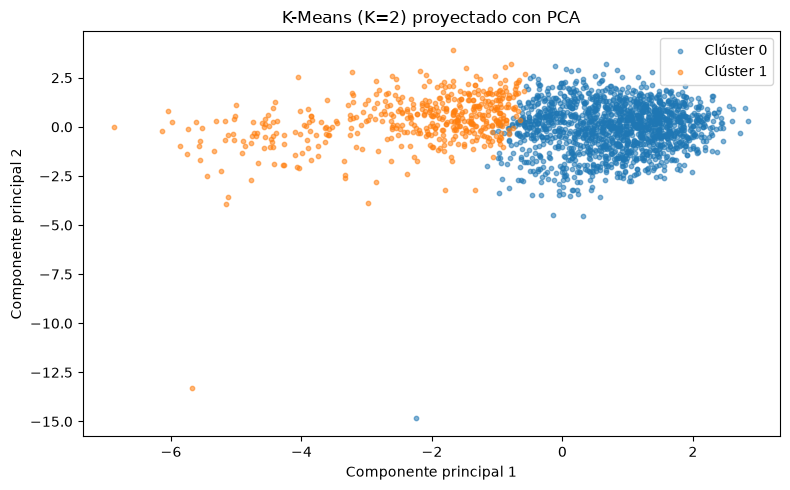

PCA conserva 44.1% de varianza en dos dimensiones (28.9% + 15.2%).
La proyección sirve para visualizar; K-Means se ajustó sobre las diez variables escaladas.


In [8]:
cluster_scaler = StandardScaler().fit(train_data[list(NUMERIC_FEATURES)])
cluster_features = cluster_scaler.transform(train_data[list(NUMERIC_FEATURES)])
sample_indices = np.random.default_rng(SEED).choice(len(train_data), size=min(2_000, len(train_data)), replace=False)
cluster_rows, cluster_fits = [], {}
for k in range(2, 9):
    fitted = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_features)
    cluster_fits[k] = fitted
    sample_labels = fitted.labels_[sample_indices]
    cluster_rows.append({
        "K": k, "inercia": fitted.inertia_,
        "silueta_muestra": silhouette_score(cluster_features[sample_indices], sample_labels),
        "grupo_mínimo_pct": 100 * np.bincount(fitted.labels_).min() / len(train_data),
    })
cluster_evidence = pd.DataFrame(cluster_rows)
display(cluster_evidence.round(3))
eligible = cluster_evidence.loc[cluster_evidence["grupo_mínimo_pct"].ge(1)]
chosen_k = int(eligible.sort_values(["silueta_muestra", "K"], ascending=[False, True]).iloc[0]["K"])
chosen_clustering = cluster_fits[chosen_k]
profile_frame = train_data[list(NUMERIC_FEATURES) + ["popularity"]].copy()
profile_frame["cluster"] = chosen_clustering.labels_
cluster_profile = profile_frame.groupby("cluster").agg(
    canciones=("popularity", "size"),
    **{column: (column, "median") for column in NUMERIC_FEATURES},
    popularidad_mediana=("popularity", "median"),
).round(3)
print(f"K elegido: {chosen_k}")
display(cluster_profile)

pca = PCA(n_components=2, random_state=SEED).fit(cluster_features)
projection = pca.transform(cluster_features[sample_indices])
fig, ax = plt.subplots(figsize=(8, 5))
for cluster_id in range(chosen_k):
    mask = chosen_clustering.labels_[sample_indices] == cluster_id
    ax.scatter(projection[mask, 0], projection[mask, 1], s=10, alpha=0.55, label=f"Clúster {cluster_id}")
ax.set(xlabel="Componente principal 1", ylabel="Componente principal 2", title=f"K-Means (K={chosen_k}) proyectado con PCA")
ax.legend()
fig.tight_layout()
figure_dir = PROJECT_PATHS.figures / "ea2"
figure_dir.mkdir(parents=True, exist_ok=True)
cluster_figure_path = figure_dir / "05_clusters_pca.png"
fig.savefig(cluster_figure_path, dpi=160, bbox_inches="tight")
plt.show()
explained = pca.explained_variance_ratio_
print(f"PCA conserva {explained.sum():.1%} de varianza en dos dimensiones ({explained[0]:.1%} + {explained[1]:.1%}).")
print("La proyección sirve para visualizar; K-Means se ajustó sobre las diez variables escaladas.")

### Sensibilidad de los clústeres

Se conserva K y se repite el ajuste, por separado, tras transformar la duración con `log1p` y al retirar `loudness`. ARI compara asignaciones con la solución original sin depender de los nombres de los clústeres.

In [9]:
original_numeric = train_data[list(NUMERIC_FEATURES)]
duration_log = original_numeric.copy()
duration_log["duration_ms"] = np.log1p(duration_log["duration_ms"])
without_loudness = original_numeric.drop(columns="loudness")
stability_rows = []
for label, values in (("original", original_numeric), ("duración_log1p", duration_log), ("sin_loudness", without_loudness)):
    scaled = cluster_features if label == "original" else StandardScaler().fit_transform(values)
    labels = chosen_clustering.labels_ if label == "original" else KMeans(
        n_clusters=chosen_k, random_state=SEED, n_init=10
    ).fit_predict(scaled)
    stability_rows.append({
        "variante": label, "variables": values.shape[1],
        "silueta_muestra": silhouette_score(scaled[sample_indices], labels[sample_indices]),
        "ARI_vs_original": adjusted_rand_score(chosen_clustering.labels_, labels),
        "grupo_0": int(np.sum(labels == 0)), "grupo_1": int(np.sum(labels == 1)),
    })
stability = pd.DataFrame(stability_rows)
display(stability.round(3))

,variante,variables,silueta_muestra,ARI_vs_original,grupo_0,grupo_1
0,original,10,0.245,1.000,54011,17781
1,duración_log1p,10,0.241,0.968,53954,17838
2,sin_loudness,9,0.209,0.807,51769,20023


## 8. Comparación integrada y conclusiones

La tabla final pone la prueba aleatoria y la prueba agrupada en sus propios contextos; no se deben comparar como si fueran las mismas canciones. Un MAE menor que Dummy muestra señal predictiva en esta muestra, pero no acredita utilidad comercial ni predicción de éxito futuro. La prueba aleatoria puede compartir artistas; la prueba agrupada excluye artistas principales, aunque las colaboraciones secundarias se superponen.

In [10]:
random_summary = random_test[["variante", "modelo", "MAE", "RMSE", "R2", "mejora_MAE_pct"]].copy()
random_summary.insert(0, "partición", "aleatoria")
artist_summary = artist_test_scores[["modelo", "MAE", "RMSE", "R2", "mejora_MAE_pct"]].copy()
artist_summary.insert(0, "variante", "completo")
artist_summary.insert(0, "partición", "por artista principal")
combined_results = pd.concat([random_summary, artist_summary], ignore_index=True)
display(combined_results.round(3))

print(f"MAE Ridge completo, aleatorio: {random_summary.loc[random_summary['modelo'].eq('Ridge') & random_summary['variante'].eq('completo'), 'MAE'].iloc[0]:.3f}")
print(f"MAE de Dummy, aleatorio: {random_summary.loc[random_summary['modelo'].eq('Dummy mediana'), 'MAE'].iloc[0]:.3f}")
print(f"KPI Ridge en prueba aleatoria: precisión {random_kpi['precision']:.1%}, recall {random_kpi['recall']:.1%}, lift {random_kpi['lift']:.3f}")
print(f"Clústeres seleccionados: K={chosen_k}; PCA 2D: {explained.sum():.1%} de varianza explicada")

# Guardar tablas reproducibles que pueden consumirse en informes y diapositivas.
summary_path = figure_dir / "05_model_comparison_results.csv"
combined_results.to_csv(summary_path, index=False, encoding="utf-8")
print(f"Tabla guardada en: {summary_path.relative_to(PROJECT_PATHS.root)}")

,partición,variante,modelo,MAE,RMSE,R2,mejora_MAE_pct
0,aleatoria,completo,Ridge,11.915,16.643,0.348,30.929
1,aleatoria,completo,Árbol,14.508,18.460,0.198,15.898
2,aleatoria,sin_géneros,Árbol,15.693,19.834,0.074,9.026
3,aleatoria,sin_géneros,Ridge,16.671,20.223,0.037,3.360
4,aleatoria,referencia,Dummy mediana,17.250,20.612,-0.000,0.000
5,por artista principal,completo,Dummy mediana,16.707,20.075,-0.003,0.000
6,por artista principal,completo,Ridge,12.102,16.740,0.302,27.564
7,por artista principal,completo,Árbol,14.455,18.247,0.171,13.479


MAE Ridge completo, aleatorio: 11.915
MAE de Dummy, aleatorio: 17.250
KPI Ridge en prueba aleatoria: precisión 8.9%, recall 24.3%, lift 2.435
Clústeres seleccionados: K=2; PCA 2D: 44.1% de varianza explicada
Tabla guardada en: reports\figures\ea2\05_model_comparison_results.csv


### Lectura para el equipo

- En la prueba aleatoria, el Ridge completo reduce el MAE frente a Dummy; el árbol mejora la referencia, aunque queda por detrás de Ridge.
- Añadir géneros aporta gran parte de la mejora observada en Ridge. La transformación de duración y el escalado robusto producen diferencias pequeñas frente al tratamiento estándar.
- Al reservar artistas principales, Ridge sigue mejor que la referencia, con métricas propias de esa partición. La superposición de colaboradores secundarios impide describirla como prueba de artistas completamente desconocidos.
- El ranking retrospectivo del 10 % mejora sobre una selección aleatoria en la prueba, pero no prueba eficacia comercial. La popularidad ya está presente en la fuente como objetivo histórico.
- K-Means entrega perfiles exploratorios. Dos componentes PCA explican 44,1 % de la varianza: la visualización pierde el resto de la información.
- La fuente está balanceada artificialmente por género y no contiene fecha de lanzamiento, región, playlists ni exposición promocional. No hay evaluación temporal, causal ni de lanzamientos futuros.